## Read the data

In [21]:
import numpy as np
import pandas as pd
import sys
PATH_TO_PREDICTOR_HOME = "../.."
sys.path.append(PATH_TO_PREDICTOR_HOME)
METHOD = "hmm_pomegranate"

In [22]:
DATA_PATH = 'D:/Google Drive/Work/ITMO/data/length_dependent_hmm/per_length_per_kfold_split/' # windows
# DATA_PATH = '/home/denklewer/Data/length_dependent_hmm/' #ubuntu
TARGET_PATH_TO_RESULTS = "experiment_results/alleles_with_groups_balanced/"


In [23]:
from data_reading_methods import get_available_alleles, read_data

ALLELES = list(sorted(get_available_alleles(DATA_PATH)))

per_allele_per_kfold_per_length_binders_train = read_data(DATA_PATH, ALLELES, "train", "binders")
per_allele_per_kfold_per_length_binders_test = read_data(DATA_PATH, ALLELES, "test", "binders")
per_allele_per_kfold_per_length_non_binders_train = read_data(DATA_PATH, ALLELES, "train", "nonbinders")
per_allele_per_kfold_per_length_non_binders_test = read_data(DATA_PATH, ALLELES, "test", "nonbinders")
ALLELES = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01']
ALLELES

['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01']

# Read models

In [24]:
## PARAMETERS
RUNS = 2
total_splits = 1
TARGET_LENGTHS = [9, 10]

In [25]:
from hmm_logic_methods import load_model

In [26]:
import itertools

target_length_string = "-".join([str(l) for l in TARGET_LENGTHS])
max_target_length = max(TARGET_LENGTHS)


name_to_run = dict()
name_to_split = dict()
name_to_type = dict()
name_to_model_root = dict()
selected_binding_models = list()
per_name_binding_model = dict()


def populate_models_infos(model_name, run_num, split_num, model_path, model_type ):
    selected_binding_models.append(model_name)

    name_to_run[model_name] = run_num
    name_to_split[model_name] = split_num
    name_to_model_root[model_name] = model_path
    assert model_type in ["bw", "v", "bwv", "bw-it", "bwv-it", "v-it"] or "mixed" in model_type
    name_to_type[model_name] = model_type


# states = 3
combinations_size = len(ALLELES)
# combinations_size = 2
# # MODELS_PATH = f"experiment_results/iterative_all_alleles_{states}perposition/"
# # MODELS_PATH = f"experiment_results/iterative_alleles_{states}perposition/"
# MODELS_PATH = f"experiment_results/iterative_alleles_{states}perposition_pc10/"
MIXED_ALLELES = list()
for combination in itertools.combinations(ALLELES, combinations_size):
    allele_name = "+".join(combination)
    # allele_name = f"{allele_name1}+{allele_name2}"
    MIXED_ALLELES.append(allele_name)

MODELS_PATH = f"experiment_results/alleles_with_groups_balanced/"
states = 25
for allele_name in MIXED_ALLELES:
    target_allele_name = allele_name.replace('-', '_').replace('*', '_').replace(':', '_')
    for run_num_b in range(RUNS):
        for split_num_b in range(total_splits):
            #bw
            bw_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}"
            populate_models_infos(bw_model_name, run_num_b,split_num_b, MODELS_PATH, f"bw-it-mixed({target_allele_name})")
            #bwv
            bwv_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{target_allele_name}-{split_num_b}_plus_viterbi"
            populate_models_infos(bwv_model_name, run_num_b,split_num_b, MODELS_PATH, f"bwv-it-mixed({target_allele_name})")
            #v
            v_model_name = f"{run_num_b}_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{target_allele_name}-{split_num_b}"
            populate_models_infos(v_model_name, run_num_b,split_num_b, MODELS_PATH, f"v-it-mixed({target_allele_name})")


for model_name in selected_binding_models:
    per_name_binding_model[model_name] =  load_model(name_to_model_root[model_name], model_name)

In [27]:
per_name_binding_model.keys()

dict_keys(['0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0', '0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi', '0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0', '1_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0', '1_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi', '1_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0'])

# Extract all possible paths (Now calculate for 1 BW + 1 V + 1 BWV)

In [28]:
import importlib
import hmm_logic_methods
importlib.reload(hmm_logic_methods)

<module 'hmm_logic_methods' from 'D:\\Projects\\MHC_predictor\\experiments\\length_dependent_hmm\\hmm_logic_methods.py'>

## Prepare: select models

In [29]:
# combination = "HLA_A_01_01+HLA_A_02_01+HLA_A_03_01+HLA_B_07_02+HLA_B_27_05"
# selected_alleles = ['HLA-A*01:01', 'HLA-A*02:01', 'HLA-A*03:01', 'HLA-B*07:02', 'HLA-B*27:05']
# selected_alleles = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-B*07:02']
selected_alleles = ['HLA-A*01:01', 'HLA-A*03:01', 'HLA-A*02:01']
combination = "+".join(selected_alleles).replace('-', '_').replace('*', '_').replace(':', '_')

# iterative models
# mixed_model_bw =f'0_run-9-{states}-st-baum-welch-alg-5-min_iters_model-{combination}-0_iterations_to_length_9'
# mixed_model_bwv = f'0_run-9-{states}-st-baum-welch-alg-5-min_iters_model-{combination}-0_iterations_to_length_9_plus_viterbi'
# mixed_model_v = f'0_run-9-{states}-st-viterbi-alg-5-min_iters_model-{combination}-0_iterations_to_length_9'
#

# simple models
# states = 25
mixed_model_bw =f'0_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{combination}-0'
mixed_model_bwv = f'0_run-{target_length_string}-{states}-st-baum-welch-alg-5-min_iters_model-{combination}-0_plus_viterbi'
mixed_model_v = f'0_run-{target_length_string}-{states}-st-viterbi-alg-5-min_iters_model-{combination}-0'

In [30]:
model_bw = per_name_binding_model[mixed_model_bw]
model_bwv = per_name_binding_model[mixed_model_bwv]
model_v = per_name_binding_model[mixed_model_v]

## Extracting paths
* precision used to crop transitions
* min and max path lengths are  min/max of (TARGET_LENGTHS)

In [12]:
# Get top paths
from hmm_logic_methods import get_all_paths_with_probs, get_model_representation

In [12]:
%%time
df_bw_paths, edge_to_prob_bw = get_all_paths_with_probs(model_bw, cutoff=max(TARGET_LENGTHS), precision=3, min_path_length=min(TARGET_LENGTHS), max_path_length=max(TARGET_LENGTHS))
df_bwv_paths, edge_to_prob_bwv = get_all_paths_with_probs(model_bwv, cutoff=max(TARGET_LENGTHS), precision=3, min_path_length=min(TARGET_LENGTHS), max_path_length=max(TARGET_LENGTHS))
df_v_paths, edge_to_prob_v = get_all_paths_with_probs(model_v, cutoff=max(TARGET_LENGTHS), precision=2, min_path_length=min(TARGET_LENGTHS), max_path_length=max(TARGET_LENGTHS))


Converting graph for model (0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0) (Delete zero edges)
Path finding (slow operation)...
	Condition: Took only paths with transitions above 0.001...
	Condition: Cutoff for path finding was 10...
	Condition: Took only paths of acceptable lengths: min 9 , max 10...


415620it [00:06, 66181.02it/s]


Paths with correct length: 73872
Calculating probs for selected paths...


100%|██████████| 73872/73872 [00:00<00:00, 94524.80it/s] 


Converting graph for model (0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi) (Delete zero edges)
Path finding (slow operation)...
	Condition: Took only paths with transitions above 0.001...
	Condition: Cutoff for path finding was 10...
	Condition: Took only paths of acceptable lengths: min 9 , max 10...


480794it [00:05, 82398.31it/s] 


... (3 outputs left out)

206543121it [21:27, 160431.41it/s]


Paths with correct length: 49737285
Calculating probs for selected paths...


100%|██████████| 49737285/49737285 [08:30<00:00, 97356.35it/s] 


Wall time: 34min 50s


In [13]:
df_bw_paths

,path,prob,normalized_prob,len
0,grouped_model-start>s003>s001>s009>s006>s012>s...,-3.939678,-0.358153,9
1,grouped_model-start>s003>s001>s009>s006>s012>s...,-4.306566,-0.391506,9
2,grouped_model-start>s003>s001>s009>s006>s012>s...,-4.317318,-0.392483,9
3,grouped_model-start>s003>s001>s009>s006>s012>s...,-4.706226,-0.427839,9
4,grouped_model-start>s003>s001>s009>s006>s014>s...,-4.879030,-0.443548,9
...,...,...,...,...
73867,grouped_model-start>s000>s004>s007>s006>s010>s...,-26.603480,-2.216957,10
73868,grouped_model-start>s000>s004>s007>s006>s010>s...,-26.668079,-2.222340,10
73869,grouped_model-start>s003>s004>s007>s006>s010>s...,-26.668260,-2.222355,10
73870,grouped_model-start>s003>s004>s007>s006>s010>s...,-26.757127,-2.229761,10


## Save paths to corresponding model folder

In [14]:
def save_paths_df(paths_df, model):
    print(f"model {model.name}")
    TARGET_PATH_TO_FILES = TARGET_PATH_TO_RESULTS + model.name
    paths_df.to_csv("{}/total_paths_df.csv".format(TARGET_PATH_TO_FILES),sep=";", index=False)

# bw model
save_paths_df(df_bw_paths, model_bw)

# bwv model
save_paths_df(df_bwv_paths, model_bwv)

# v model
save_paths_df(df_v_paths, model_v)


model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0


# Extract only viterbi paths for models
* we need some data here

## Preparation: get decoy data

In [31]:
from mhcgnomes import parse
# decoy data
def defineOrganism(allele_name):
    parse_result = parse(allele_name)
    if parse_result.is_mouse:
        return "Mouse"
    elif parse_result.is_human:
        return "Human"
    else:
        print("organism not found")
        return None

def defineClass(allele_name):
    parse_result = parse(allele_name)
    if parse_result.has_mhc_class:
        if parse_result.is_class1:
            return 'I'
        elif parse_result.is_class2:
            return 'II'
        else:
            print("Not class I or class II???!")
    else:
        print("Result without class")
    return None

per_allele_decoy_peptides = dict()
for allele_name in ALLELES:
    organism =  defineOrganism(allele_name).lower()
    class_to_use = defineClass(allele_name)
    DECOY_DATA_PATH = f"D:\Google Drive\Work\ITMO\data\decoy\sampled_decoy_data_{organism}_class_{class_to_use}.csv"
    decoy_df =  pd.read_csv(DECOY_DATA_PATH)
    decoy_df['length'] = decoy_df['peptide'].str.len()
    per_allele_decoy_peptides[allele_name] = decoy_df.copy()[decoy_df['length'].isin(TARGET_LENGTHS)]['peptide'].values

peptides_for_analysis = np.unique(np.concatenate([value for key, value in per_allele_decoy_peptides.items()
                                                  if key in selected_alleles]))

In [32]:
len(peptides_for_analysis)

802687

## Calculate viterbi paths

In [33]:
peptide = peptides_for_analysis[0]
logp, path = model_v.viterbi(peptide)
print("Viterbi for Sequence: '{}'  -- Log Probability: {} -- Path: {}".format(''.join( peptide ), logp, " ".join( state.name for idx, state in path[1:-1] ) ))

Viterbi for Sequence: 'AAAAAAAAA'  -- Log Probability: -36.18985347682547 -- Path: s004 s009 s005 s009 s005 s014 s017 s023 s022


In [34]:
import importlib
import hmm_logic_methods
importlib.reload(hmm_logic_methods)

<module 'hmm_logic_methods' from 'D:\\Projects\\MHC_predictor\\experiments\\length_dependent_hmm\\hmm_logic_methods.py'>

In [35]:
from hmm_logic_methods import get_all_viterbi_paths_for_model_and_sequences


df_bw_paths = get_all_viterbi_paths_for_model_and_sequences(model_bw, peptides_for_analysis)
df_bwv_paths = get_all_viterbi_paths_for_model_and_sequences(model_bwv, peptides_for_analysis)
df_v_paths = get_all_viterbi_paths_for_model_and_sequences(model_v, peptides_for_analysis)

Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
Get viterbi paths for each peptide...


100%|██████████| 802687/802687 [00:18<00:00, 43819.58it/s]


Select unique paths...
	Unique paths: 1518


100%|██████████| 1518/1518 [00:00<00:00, 126526.77it/s]


Model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi
Get viterbi paths for each peptide...


100%|██████████| 802687/802687 [00:18<00:00, 44154.63it/s]


... (2 outputs left out)

Model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
Get viterbi paths for each peptide...


100%|██████████| 802687/802687 [00:23<00:00, 34200.56it/s]


Select unique paths...
	Unique paths: 742916


100%|██████████| 742916/742916 [00:08<00:00, 90737.45it/s] 


In [36]:
df_v_paths

,path,prob,normalized_prob,len
0,grouped_model-start>s004>s002>s007>s008>s012>s...,-12.139394,-1.103581,9
1,grouped_model-start>s004>s002>s001>s002>s005>s...,-12.311142,-1.119195,9
2,grouped_model-start>s004>s002>s001>s002>s006>s...,-12.353296,-1.123027,9
3,grouped_model-start>s004>s002>s008>s012>s013>s...,-12.357429,-1.123403,9
4,grouped_model-start>s004>s007>s008>s012>s013>s...,-12.372824,-1.124802,9
...,...,...,...,...
742911,grouped_model-start>s002>s006>s013>s015>s019>s...,-31.444015,-2.620335,10
742912,grouped_model-start>s004>s005>s008>s009>s007>s...,-31.592777,-2.632731,10
742913,grouped_model-start>s004>s009>s011>s015>s019>s...,-31.598601,-2.633217,10
742914,grouped_model-start>s004>s008>s006>s013>s012>s...,-31.626152,-2.635513,10


## Save paths to corresponding model folder

In [37]:
def save_paths_df(paths_df, model):
    print(f"model {model.name}")
    TARGET_PATH_TO_FILES = TARGET_PATH_TO_RESULTS + model.name
    paths_df.to_csv("{}/viterbi_paths_df.csv".format(TARGET_PATH_TO_FILES),sep=";", index=False)

# bw model
save_paths_df(df_bw_paths, model_bw)

# bwv model
save_paths_df(df_bwv_paths, model_bwv)

# v model
save_paths_df(df_v_paths, model_v)


model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0
model 0_run-9-10-25-st-baum-welch-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0_plus_viterbi
model 0_run-9-10-25-st-viterbi-alg-5-min_iters_model-HLA_A_01_01+HLA_A_03_01+HLA_A_02_01-0


In [38]:
df_bw_paths

,path,prob,normalized_prob,len
0,grouped_model-start>s002>s003>s006>s013>s010>s...,-4.950725,-0.412560,10
1,grouped_model-start>s002>s003>s006>s013>s012>s...,-5.051977,-0.420998,10
2,grouped_model-start>s002>s003>s006>s013>s010>s...,-5.135306,-0.427942,10
3,grouped_model-start>s002>s003>s006>s013>s012>s...,-5.236558,-0.436380,10
4,grouped_model-start>s002>s003>s006>s013>s010>s...,-4.862546,-0.442050,9
...,...,...,...,...
1513,grouped_model-start>s004>s002>s008>s009>s013>s...,-15.345073,-1.278756,10
1514,grouped_model-start>s000>s002>s008>s009>s013>s...,-15.362351,-1.280196,10
1515,grouped_model-start>s000>s002>s003>s006>s013>s...,-15.442132,-1.286844,10
1516,grouped_model-start>s001>s000>s008>s006>s005>s...,-16.265387,-1.355449,10


## Probability distribution

In [15]:
df_bwv_paths['exp_prob'] = np.exp(df_bwv_paths['prob'])
df_v_paths['exp_prob'] = np.exp(df_v_paths['prob'])
df_bw_paths['exp_prob'] = np.exp(df_bw_paths['prob'])

In [16]:
df_bwv_paths['exp_prob'].cumsum().iloc[10]

0.7741568823629214

In [32]:
df_v_paths['exp_prob'].cumsum().iloc[100000]

0.10975746086126441

<AxesSubplot:>

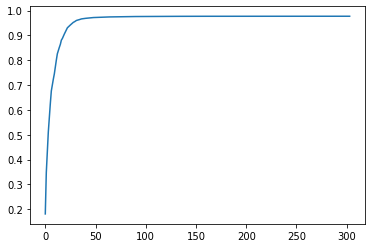

In [34]:
df_bwv_paths['exp_prob'].cumsum().plot()

<AxesSubplot:>

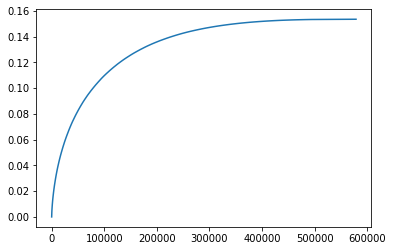

In [35]:
df_v_paths['exp_prob'].cumsum().plot()

<AxesSubplot:>

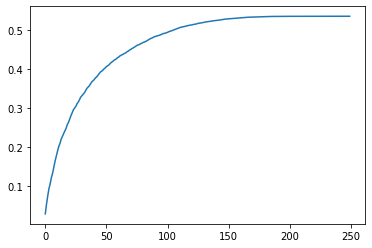

In [36]:
df_bw_paths['exp_prob'].cumsum().plot()

<AxesSubplot:ylabel='exp_prob'>

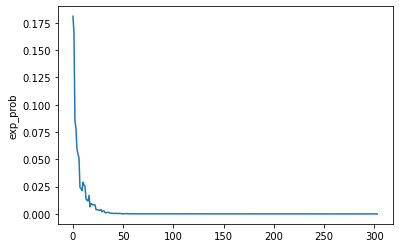

In [37]:
import seaborn as sns
sns.lineplot(data=df_bwv_paths, x=df_bwv_paths.index.values, y='exp_prob')

<AxesSubplot:ylabel='exp_prob'>

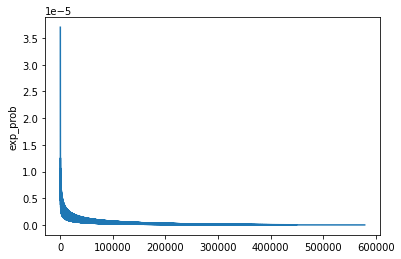

In [38]:
sns.lineplot(data=df_v_paths, x=df_v_paths.index.values, y='exp_prob')

<AxesSubplot:ylabel='exp_prob'>

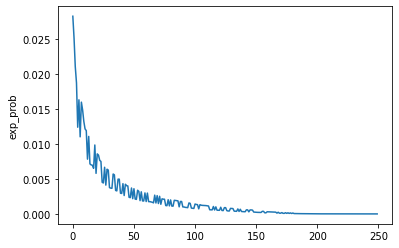

In [39]:
sns.lineplot(data=df_bw_paths, x=df_bw_paths.index.values, y='exp_prob')

In [124]:
#paths probs 3 per position
df_bw_paths.describe()

,prob,exp_prob
count,19683.000000,1.968300e+04
mean,-10.857784,5.080526e-05
std,1.630386,6.636808e-05
min,-15.265151,2.346548e-07
25%,-12.137985,5.352296e-06
50%,-10.528127,2.677272e-05
75%,-9.574887,6.945114e-05
max,-7.397044,6.130621e-04
